# Clustering di dipinti con DINOv2 + UMAP + HDBSCAN/DBSCAN
Versione corretta. Modifica solo la cella di configurazione qui sotto.

In [1]:
import os

# ── CONFIGURAZIONE ────────────────────────────────────────────
# Lascia attivo un solo percorso
dataset_path = r'C:\Users\Asus\Desktop\progetto_caravaggio\dataset\genere\bianco_e_nero\Female'
#dataset_path = r'C:\Users\Asus\Desktop\progetto_caravaggio\dataset\originali\caravaggio'
#dataset_path = '/content/drive/MyDrive/Aridataset/caravaggio_2/caravaggio_bw/caravaggio_cropped/FemaleCaravaggio'

TEST_FILE = "Unknown.jpg"   # immagine da cercare nei cluster (deve stare nella cartella del dataset)

if not os.path.isdir(dataset_path):
    raise FileNotFoundError(f"Cartella non trovata: {dataset_path}\nControlla il percorso (su Colab ricordati di montare Drive).")

In [2]:
import torch

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("PyTorch:", torch.__version__)
print("Device:", device, f"({torch.cuda.get_device_name(0)})" if device.type == 'cuda' else "(nessuna GPU: uso la CPU, sarà più lento)")

PyTorch: 2.5.1+cu121
Device: cuda (NVIDIA GeForce RTX 4060 Laptop GPU)


In [3]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torchvision.transforms as T
import umap
from PIL import Image
from tqdm import tqdm
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

# hdbscan: pacchetto esterno, se manca uso quello di scikit-learn (>=1.3)
try:
    from hdbscan import HDBSCAN
except ImportError:
    from sklearn.cluster import HDBSCAN

In [4]:
model = torch.hub.load('facebookresearch/dinov2', 'dinov2_vitb14')
model.to(device)
model.eval()
print("DINOv2 pronto all'uso.")

Using cache found in C:\Users\Asus/.cache\torch\hub\facebookresearch_dinov2_main
C:\Users\Asus/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
C:\Users\Asus/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
C:\Users\Asus/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


DINOv2 pronto all'uso.


In [5]:
transform = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

valid_extensions = ('.jpg', '.jpeg', '.png', '.webp')
files = sorted(f for f in os.listdir(dataset_path) if f.lower().endswith(valid_extensions))
if not files:
    raise RuntimeError(f"Nessuna immagine trovata in {dataset_path}")
if TEST_FILE not in files:
    print(f"⚠️ '{TEST_FILE}' non è nella cartella: i grafici funzioneranno, ma senza evidenziare l'immagine di test.")

print(f"Inizio elaborazione di {len(files)} immagini...")

BATCH_SIZE = 32
all_embeddings, file_names = [], []

with torch.no_grad():
    for i in tqdm(range(0, len(files), BATCH_SIZE)):
        tensors, names = [], []
        for filename in files[i:i + BATCH_SIZE]:
            try:
                img = Image.open(os.path.join(dataset_path, filename)).convert('RGB')
                tensors.append(transform(img))
                names.append(filename)
            except Exception as e:
                print(f"Errore su {filename}: {e}")
        if not tensors:
            continue
        emb = model(torch.stack(tensors).to(device))
        all_embeddings.append(emb.cpu().numpy())
        file_names.extend(names)

X = np.vstack(all_embeddings)
X = X / np.linalg.norm(X, axis=1, keepdims=True)   # normalizzo: il prodotto scalare = similarità coseno
print(f"Matrice creata: {X.shape[0]} immagini x {X.shape[1]} caratteristiche.")

Inizio elaborazione di 44 immagini...


100%|██████████| 2/2 [00:00<00:00,  2.52it/s]

Matrice creata: 44 immagini x 768 caratteristiche.


In [6]:
# ── Funzioni di utilità ───────────────────────────────────────
def test_index():
    return file_names.index(TEST_FILE) if TEST_FILE in file_names else None

def plot_umap(labels, title):
    plt.figure(figsize=(12, 8))
    sc = plt.scatter(X_embedded[:, 0], X_embedded[:, 1], c=labels, cmap='tab20', s=15, alpha=0.7)
    plt.colorbar(sc, label='Cluster (-1 = rumore)')
    idx = test_index()
    if idx is not None:
        plt.scatter(X_embedded[idx, 0], X_embedded[idx, 1], c='red', s=200, marker='*',
                    zorder=5, label=TEST_FILE)
        plt.legend()
    plt.title(title)
    plt.show()

def show_cluster(res, title):
    """Mostra le immagini del cluster che contiene TEST_FILE."""
    if TEST_FILE not in res['file'].values:
        print(f"'{TEST_FILE}' non è nel dataset.")
        return None
    cid = res.loc[res['file'] == TEST_FILE, 'cluster'].values[0]
    print(f"'{TEST_FILE}' appartiene al cluster: {cid}")
    if cid == -1:
        print("⚠️ Classificata come RUMORE (nessun cluster). Prova a cambiare i parametri.")
        return None
    members = res.loc[res['cluster'] == cid, 'file'].tolist()
    print(f"Il cluster {cid} contiene {len(members)} immagini.")
    cols = 5
    rows = math.ceil(len(members) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(20, 4 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, name in zip(axes.ravel(), members):
        try:
            ax.imshow(Image.open(os.path.join(dataset_path, name)).convert('RGB'))
            ax.set_title(name, fontsize=9, color='red' if name == TEST_FILE else 'black')
        except Exception:
            ax.set_title(f"Errore: {name}", fontsize=8)
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()
    return members

def similarity_report(members):
    """Similarità coseno tra TEST_FILE e gli altri membri del cluster."""
    idx = test_index()
    if idx is None or not members:
        return
    rows = [{'Immagine': m, 'Similarità Coseno': round(float(X[file_names.index(m)] @ X[idx]), 4)}
            for m in members if m != TEST_FILE]
    print(f"\n--- Similarità di {TEST_FILE} con il proprio cluster ---")
    if not rows:
        print("Il cluster contiene solo l'immagine di test.")
        return
    df = pd.DataFrame(rows).sort_values('Similarità Coseno', ascending=False)
    print(df.to_string(index=False))
    print(f"\nSimilarità media: {df['Similarità Coseno'].mean():.4f}")

## Riduzione dimensionale (UMAP)

In [7]:
reducer = umap.UMAP(n_neighbors=min(15, len(X) - 1), min_dist=0.1, n_components=2, random_state=42)
X_embedded = reducer.fit_transform(X)
print("Riduzione completata: ogni immagine è un punto 2D.")

c:\Users\Asus\miniconda3\envs\caravaggio\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Riduzione completata: ogni immagine è un punto 2D.


## HDBSCAN

                                                                           file  cluster
14                         generative_ia_bw_160050_caravaggio_aligned_face0.jpg        0
18                         generative_ia_bw_160054_caravaggio_aligned_face0.jpg        0
17                         generative_ia_bw_160053_caravaggio_aligned_face0.jpg        0
16                         generative_ia_bw_160052_caravaggio_aligned_face0.jpg        0
15                         generative_ia_bw_160051_caravaggio_aligned_face0.jpg        0
13                         generative_ia_bw_160049_caravaggio_aligned_face0.jpg        0
12                         generative_ia_bw_160048_caravaggio_aligned_face0.jpg        0
10                         generative_ia_bw_160042_caravaggio_aligned_face0.jpg        0
9                          generative_ia_bw_160041_caravaggio_aligned_face0.jpg        0
11                         generative_ia_bw_160043_caravaggio_aligned_face0.jpg        0
7                    

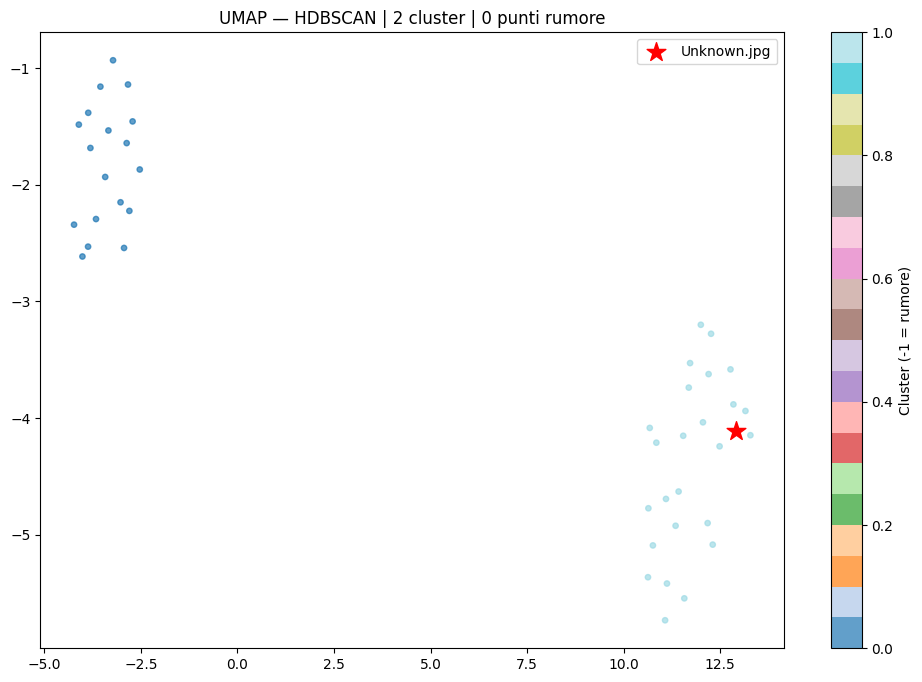

In [8]:
clusterer = HDBSCAN(min_cluster_size=5, min_samples=1)
labels = clusterer.fit_predict(X_embedded)

results = pd.DataFrame({'file': file_names, 'cluster': labels})
print(results.sort_values(by='cluster').to_string())

n_clusters_hdb = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_hdb = int((labels == -1).sum())
plot_umap(labels, f'UMAP — HDBSCAN | {n_clusters_hdb} cluster | {n_noise_hdb} punti rumore')

'Unknown.jpg' appartiene al cluster: 1
Il cluster 1 contiene 26 immagini.


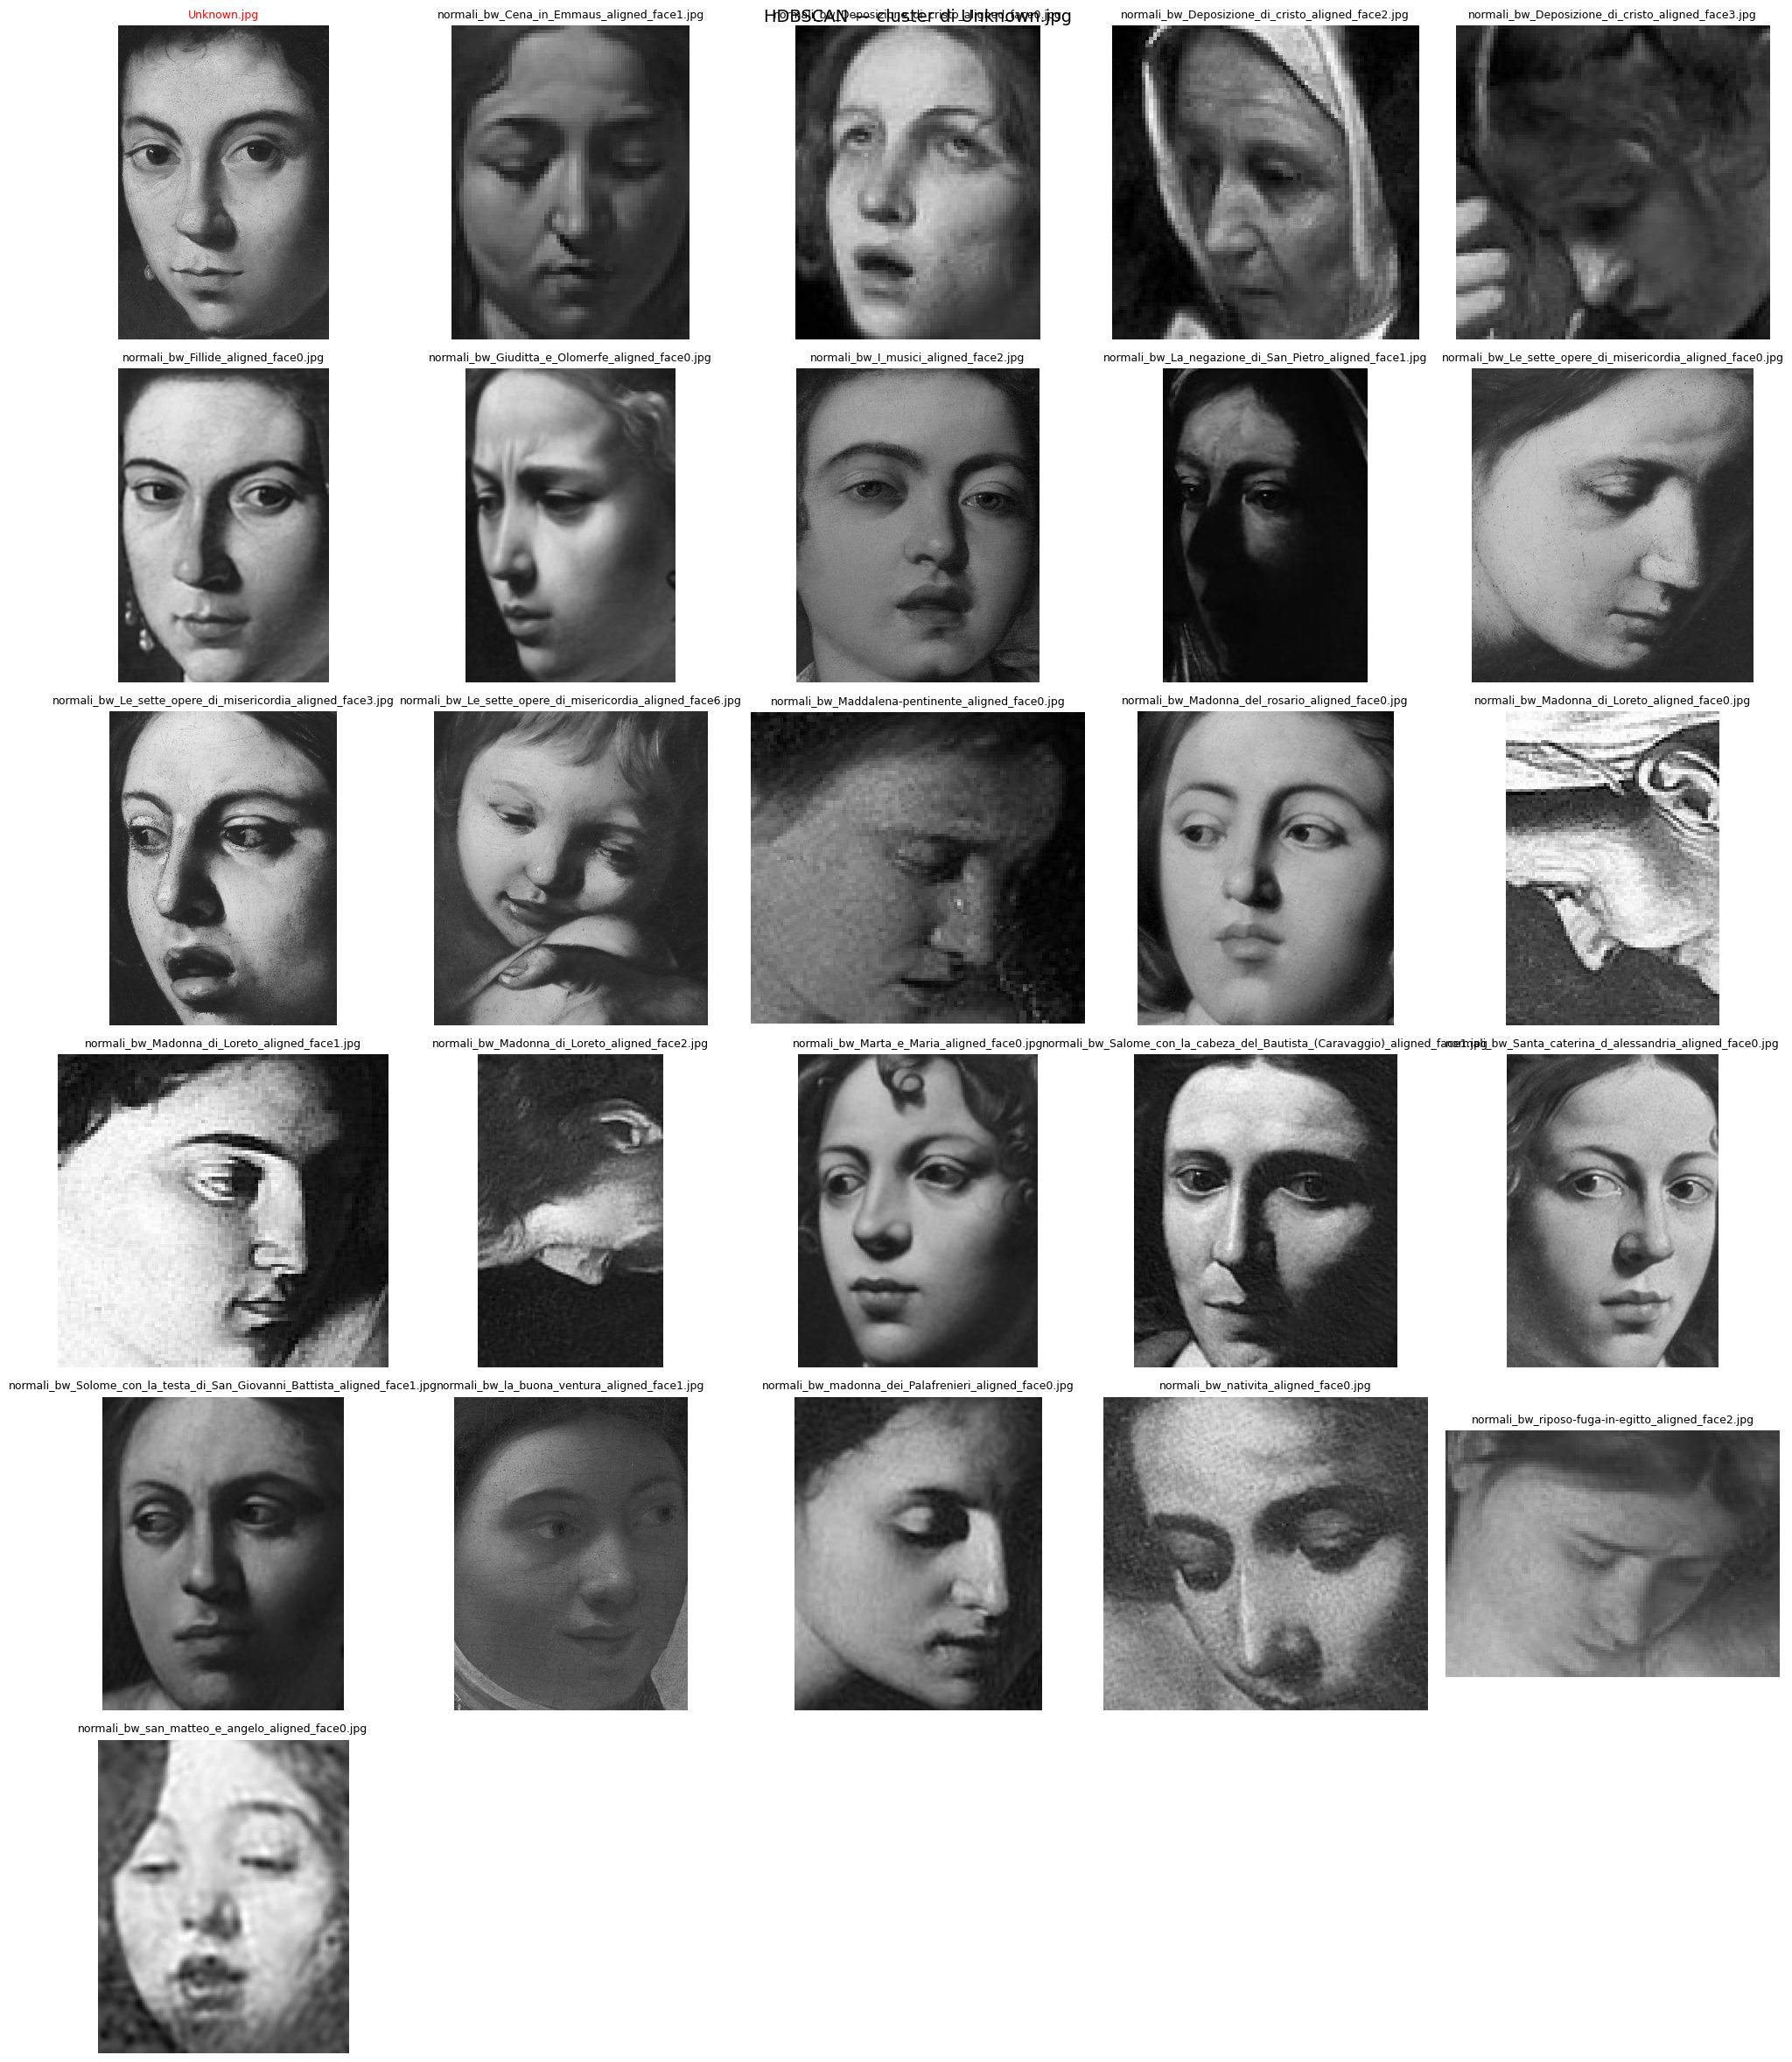


--- Similarità di Unknown.jpg con il proprio cluster ---
                                                                   Immagine  Similarità Coseno
                           normali_bw_Madonna_del_rosario_aligned_face0.jpg             0.8406
                                      normali_bw_I_musici_aligned_face2.jpg             0.8331
                normali_bw_Le_sette_opere_di_misericordia_aligned_face3.jpg             0.8265
                    normali_bw_La_negazione_di_San_Pietro_aligned_face1.jpg             0.8027
                                       normali_bw_Fillide_aligned_face0.jpg             0.7959
  normali_bw_Solome_con_la_testa_di_San_Giovanni_Battista_aligned_face1.jpg             0.7895
                  normali_bw_Santa_caterina_d_alessandria_aligned_face0.jpg             0.7871
normali_bw_Salome_con_la_cabeza_del_Bautista_(Caravaggio)_aligned_face1.jpg             0.7809
                              normali_bw_la_buona_ventura_aligned_face1.jpg            

In [9]:
members_hdb = show_cluster(results, 'HDBSCAN — cluster di ' + TEST_FILE)
similarity_report(members_hdb)

## DBSCAN

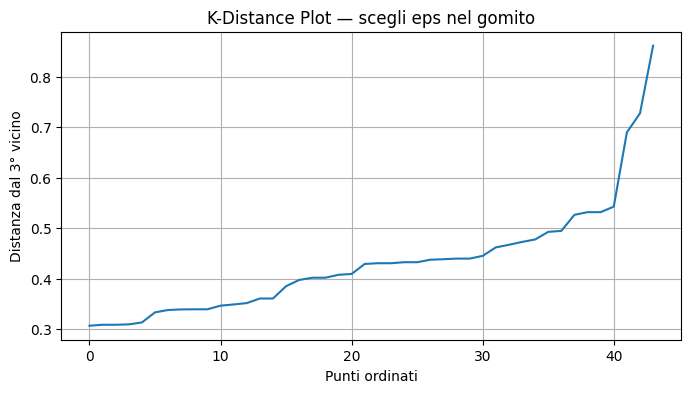

In [10]:
# ── K-Distance plot per scegliere eps ─────────────────────────
min_samples = 3
nn = NearestNeighbors(n_neighbors=min(min_samples, len(X_embedded))).fit(X_embedded)
distances, _ = nn.kneighbors(X_embedded)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_distances)
plt.xlabel('Punti ordinati')
plt.ylabel(f'Distanza dal {min_samples}° vicino')
plt.title('K-Distance Plot — scegli eps nel gomito')
plt.grid(True)
plt.show()

DBSCAN — Cluster trovati: 2 | Punti rumore: 4


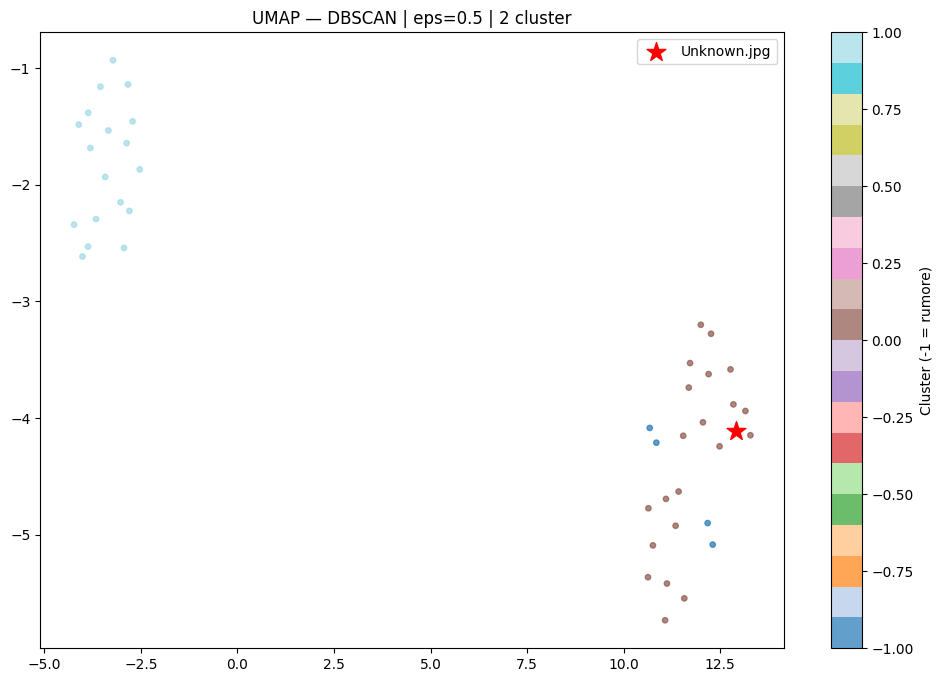

                                                                           file  cluster
32                               normali_bw_Madonna_di_Loreto_aligned_face0.jpg       -1
27                  normali_bw_Le_sette_opere_di_misericordia_aligned_face0.jpg       -1
29                  normali_bw_Le_sette_opere_di_misericordia_aligned_face6.jpg       -1
34                               normali_bw_Madonna_di_Loreto_aligned_face2.jpg       -1
24                             normali_bw_Giuditta_e_Olomerfe_aligned_face0.jpg        0
25                                        normali_bw_I_musici_aligned_face2.jpg        0
26                      normali_bw_La_negazione_di_San_Pietro_aligned_face1.jpg        0
28                  normali_bw_Le_sette_opere_di_misericordia_aligned_face3.jpg        0
30                            normali_bw_Maddalena-pentinente_aligned_face0.jpg        0
31                             normali_bw_Madonna_del_rosario_aligned_face0.jpg        0
0                    

In [11]:
eps = 0.50   # modificalo guardando il gomito del grafico sopra

labels_db = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_embedded)
n_clusters_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)
n_noise_db = int((labels_db == -1).sum())
print(f"DBSCAN — Cluster trovati: {n_clusters_db} | Punti rumore: {n_noise_db}")

plot_umap(labels_db, f'UMAP — DBSCAN | eps={eps} | {n_clusters_db} cluster')

results_db = pd.DataFrame({'file': file_names, 'cluster': labels_db})
print(results_db.sort_values(by='cluster').to_string())

'Unknown.jpg' appartiene al cluster: 0
Il cluster 0 contiene 22 immagini.


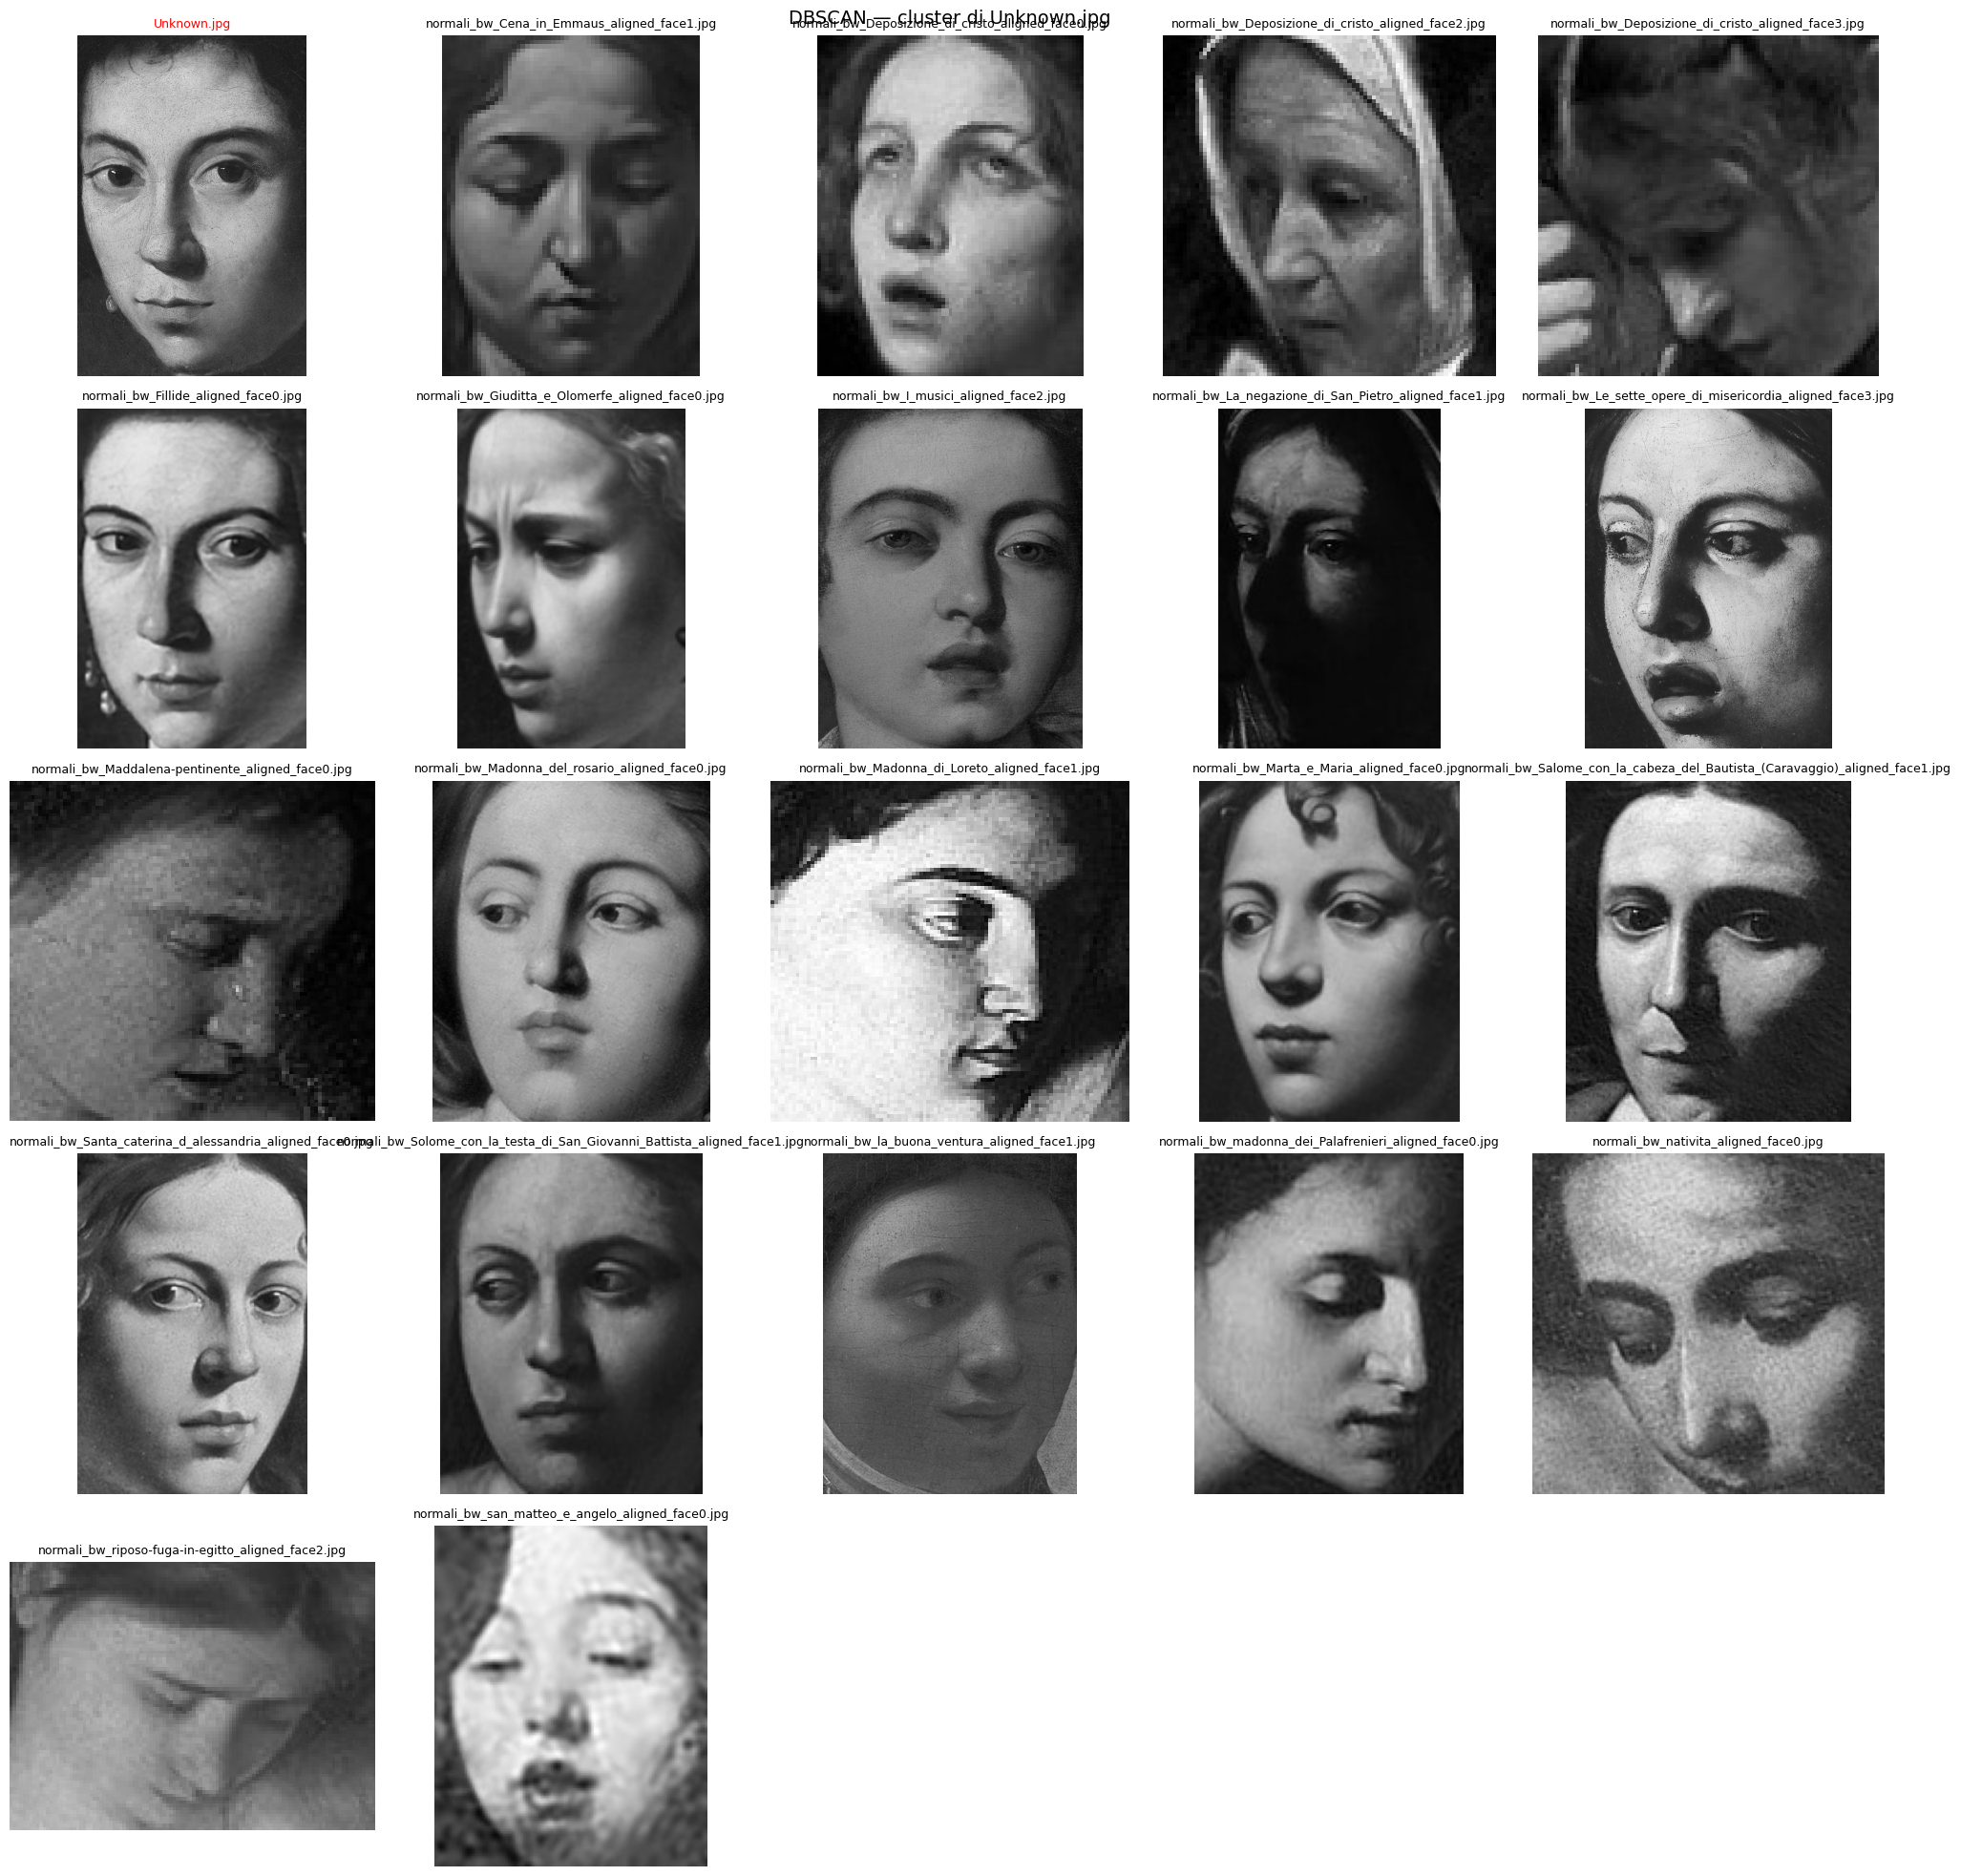


--- Similarità di Unknown.jpg con il proprio cluster ---
                                                                   Immagine  Similarità Coseno
                           normali_bw_Madonna_del_rosario_aligned_face0.jpg             0.8406
                                      normali_bw_I_musici_aligned_face2.jpg             0.8331
                normali_bw_Le_sette_opere_di_misericordia_aligned_face3.jpg             0.8265
                    normali_bw_La_negazione_di_San_Pietro_aligned_face1.jpg             0.8027
                                       normali_bw_Fillide_aligned_face0.jpg             0.7959
  normali_bw_Solome_con_la_testa_di_San_Giovanni_Battista_aligned_face1.jpg             0.7895
                  normali_bw_Santa_caterina_d_alessandria_aligned_face0.jpg             0.7871
normali_bw_Salome_con_la_cabeza_del_Bautista_(Caravaggio)_aligned_face1.jpg             0.7809
                              normali_bw_la_buona_ventura_aligned_face1.jpg            

In [12]:
members_db = show_cluster(results_db, 'DBSCAN — cluster di ' + TEST_FILE)
similarity_report(members_db)